# Customer Churn Analysis and Prediction
**AICTE | IBM SkillsBuild – Data Analytics with AI Internship 2026**

**Goal:** find out why telecom customers leave and build a machine learning model that flags customers who are likely to churn, so the company can act before they go.

**Prepared by:** Vishuddhi Jain  
**Program:** B.Tech Information Technology, Jaypee Institute of Information Technology, Noida  
**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns) – https://github.com/IBM/telco-customer-churn-on-icp4d

**Steps:** load data → clean → explore → prepare features → train models → evaluate → interpret → recommendations

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)

## 1. Load the data

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL = "Telco-Customer-Churn.csv"   # use this if you downloaded the file manually

if os.path.exists(LOCAL):
    df = pd.read_csv(LOCAL)
else:
    try:
        df = pd.read_csv(URL)
    except Exception as exc:
        raise RuntimeError(
            "Could not download the Telco churn dataset. Check your internet connection, "
            "or download the CSV from the README and place it beside this notebook as "
            "'Telco-Customer-Churn.csv'."
        ) from exc

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Clean the data

`TotalCharges` is stored as text because 11 rows contain a blank space. These are brand new customers with `tenure = 0`, so their total charges are really 0.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "Contract"]].head())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Remaining missing values:", int(df.isna().sum().sum()))

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["SeniorCitizen"] = df["SeniorCitizen"].map({1: "Yes", 0: "No"})

Missing TotalCharges: 11
      tenure  MonthlyCharges  Contract
488        0           52.55  Two year
753        0           20.25  Two year
936        0           80.85  Two year
1082       0           25.75  Two year
1340       0           56.05  Two year
Duplicate customer IDs: 0
Remaining missing values: 0


## 3. Exploratory data analysis

In [5]:
df.describe().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.27
std,24.56,30.09,2266.79,0.44
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,1.00
max,72.00,118.75,8684.80,1.00


Overall churn rate: 26.5%  (1869 of 7043 customers)


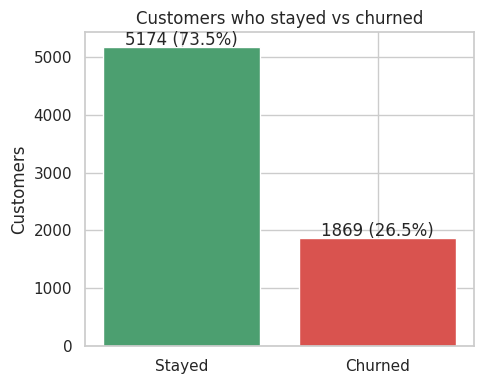

In [6]:
churn_rate = df["Churn"].mean() * 100
print(f"Overall churn rate: {churn_rate:.1f}%  ({df['Churn'].sum()} of {len(df)} customers)")

fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts()
ax.bar(counts.index, counts.values, color=["#4C9F70", "#D9534F"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v} ({v/len(df)*100:.1f}%)", ha="center")
ax.set_title("Customers who stayed vs churned")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig("images/01_churn_distribution.png", dpi=150)
plt.show()

About 1 in 4 customers churned, so the classes are imbalanced. Accuracy alone would be misleading, so recall, F1 and ROC-AUC are used later too.

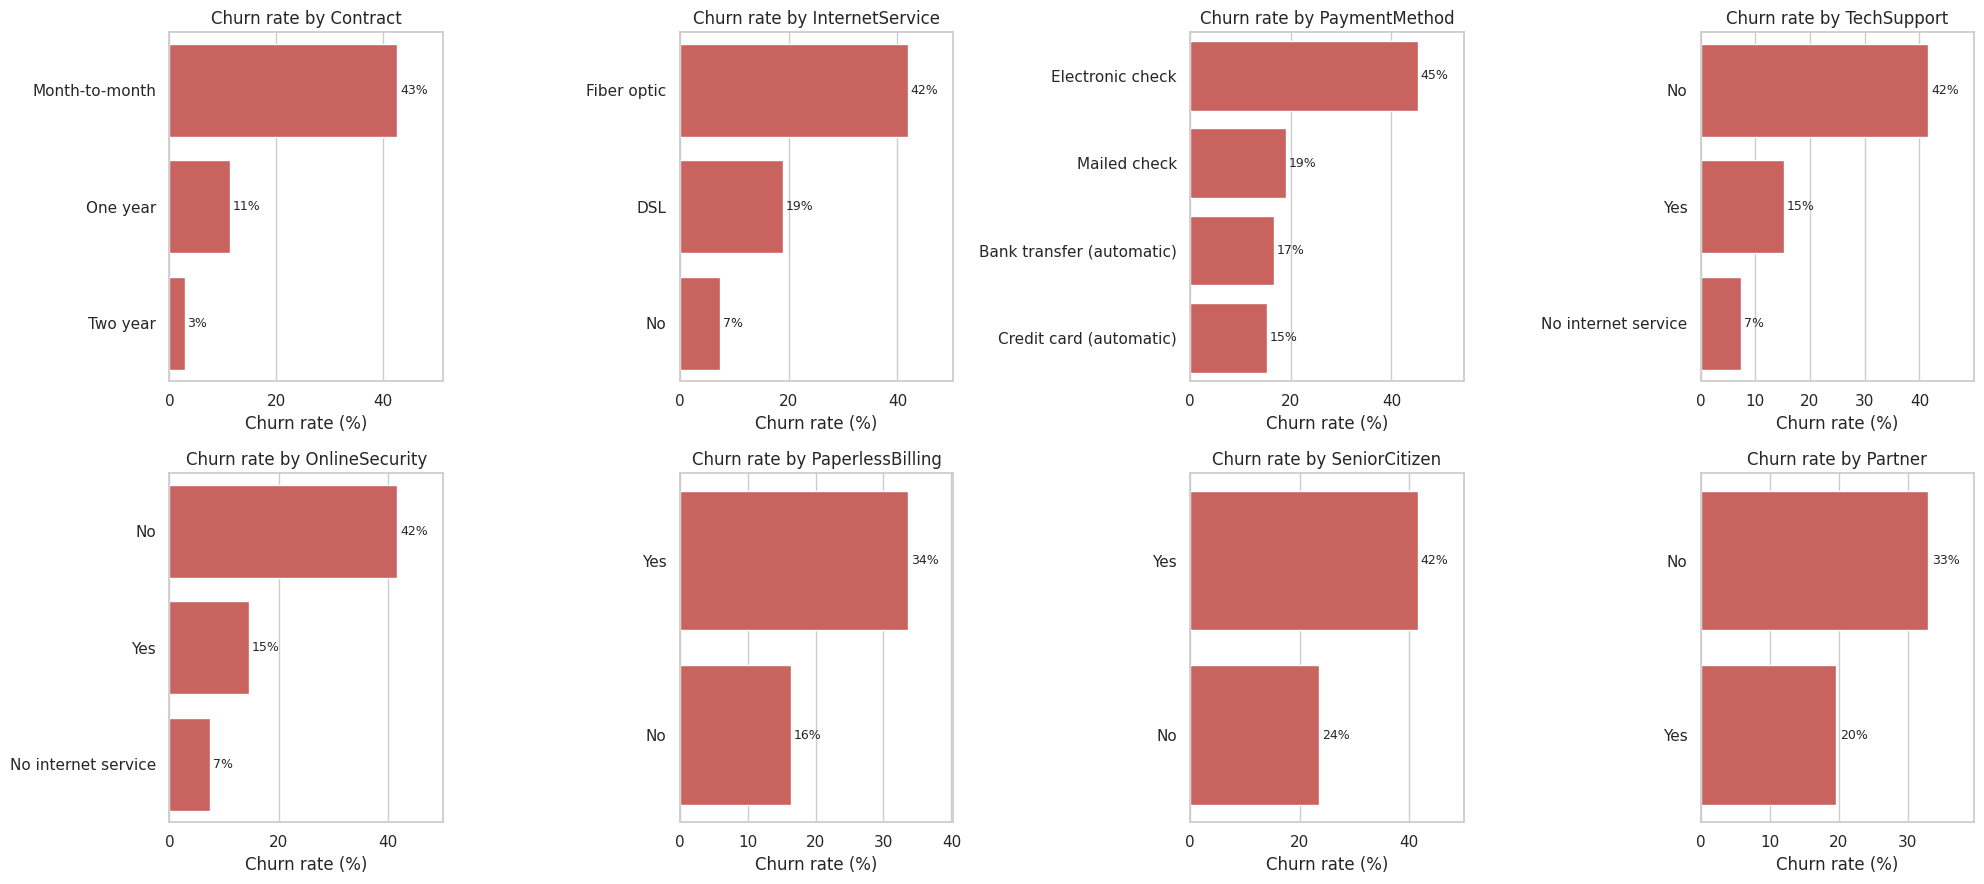

In [7]:
cat_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
            "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#D9534F")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set_xlim(0, max(rate.values) * 1.2)
plt.tight_layout()
plt.savefig("images/02_churn_by_category.png", dpi=150)
plt.show()

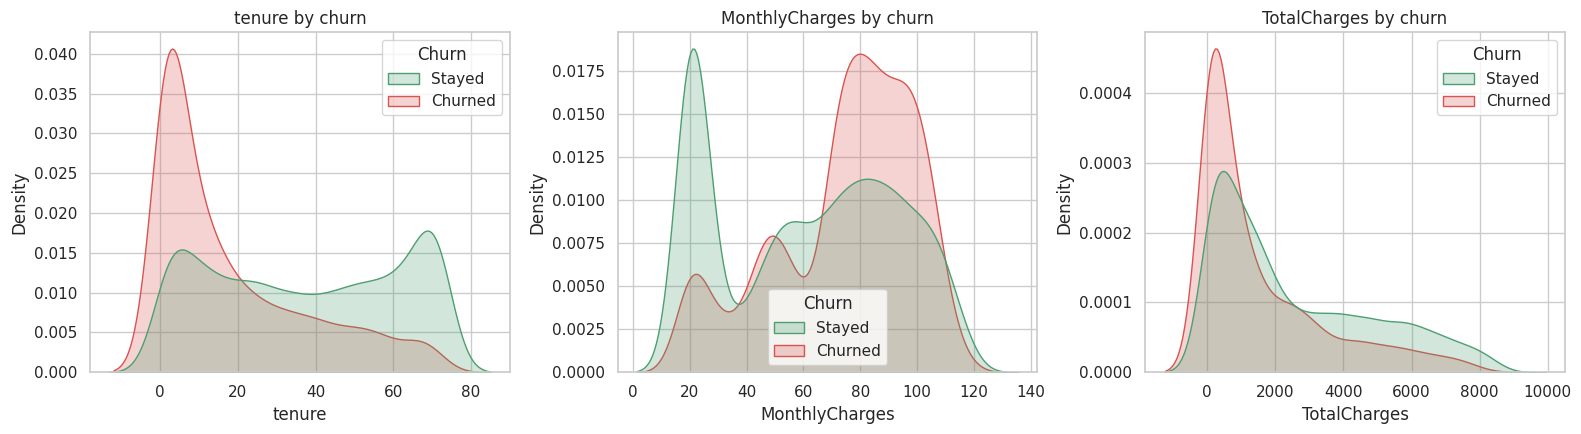

       tenure  MonthlyCharges  TotalCharges
Churn                                      
0        37.6            61.3        2549.9
1        18.0            74.4        1531.8


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df, x=col, hue=df["Churn"].map({0: "Stayed", 1: "Churned"}),
                fill=True, common_norm=False, ax=ax, palette=["#4C9F70", "#D9534F"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig("images/03_numeric_distributions.png", dpi=150)
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(1))

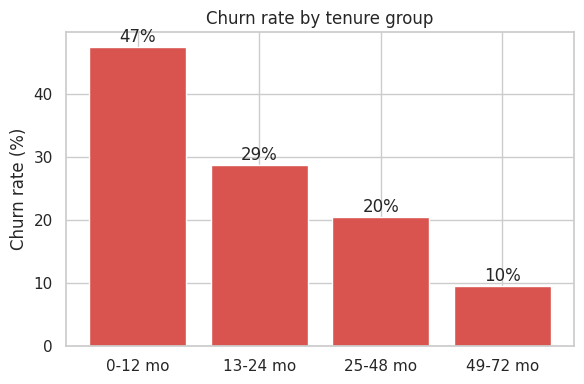

In [9]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
tg = df.groupby("TenureGroup", observed=True)["Churn"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(tg.index.astype(str), tg.values, color="#D9534F")
for i, v in enumerate(tg.values):
    ax.text(i, v + 0.8, f"{v:.0f}%", ha="center")
ax.set_title("Churn rate by tenure group")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("images/04_churn_by_tenure.png", dpi=150)
plt.show()

## 4. Prepare features

In [10]:
data = df.drop(columns=["customerID", "TenureGroup"])
y = data["Churn"]
X = pd.get_dummies(data.drop(columns="Churn"), drop_first=True)
print("Feature matrix:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Feature matrix: (7043, 30)
Train: (5634, 30) | Test: (1409, 30)
Churn rate train/test: 0.265 0.265


## 5. Train and compare models

Three models are compared. `class_weight='balanced'` is used where available so the models pay attention to the smaller churn class. In cross-validation, numeric scaling is fitted separately inside each training fold to avoid using validation-fold statistics.

In [11]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                             class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), False),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
}

rows, fitted, probas = [], {}, {}
for name, (model, scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    fitted[name], probas[name] = model, proba
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.738,0.504,0.783,0.614,0.842
Random Forest,0.774,0.556,0.749,0.638,0.844
Gradient Boosting,0.798,0.655,0.508,0.572,0.842


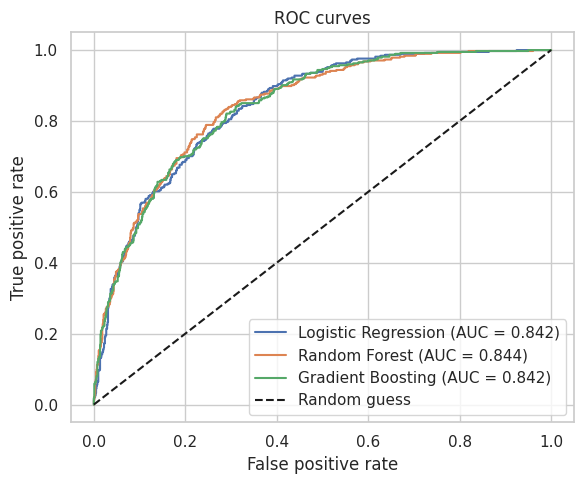

In [12]:
plt.figure(figsize=(6, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/05_roc_curves.png", dpi=150)
plt.show()

## 6. Cross-validation and best model

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, (model, scaled) in models.items():
    # Fit scaling only on each CV training fold (not on its validation fold).
    if scaled:
        numeric_preprocessor = ColumnTransformer(
            transformers=[("scale_numeric", StandardScaler(), num_cols)],
            remainder="passthrough"
        )
        cv_model = Pipeline([
            ("preprocess", numeric_preprocessor),
            ("classifier", clone(model))
        ])
    else:
        cv_model = clone(model)

    scores = cross_val_score(
        cv_model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    cv_scores[name] = (scores.mean(), scores.std())
    print(f"{name:20s} CV ROC-AUC: {scores.mean():.3f} +/- {scores.std():.3f}")

# For this demonstration, choose the model with the strongest held-out F1 score.
# A production-grade evaluation should use a validation/CV selection step and reserve
# the test split for one final, unbiased evaluation.
best_name = results["F1"].idxmax()
print("\nSelected model (highest F1 on the comparison split):", best_name)

              precision    recall  f1-score   support

      Stayed       0.90      0.78      0.84      1035
     Churned       0.56      0.75      0.64       374

    accuracy                           0.77      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.77      0.78      1409



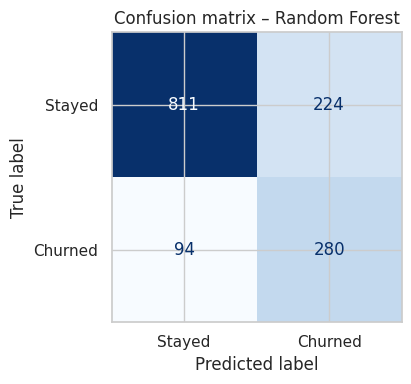

In [14]:
best_model, best_scaled = models[best_name]
Xte = X_test_s if best_scaled else X_test
pred = best_model.predict(Xte)

print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix – {best_name}")
plt.tight_layout()
plt.savefig("images/06_confusion_matrix.png", dpi=150)
plt.show()

## 7. What drives churn?

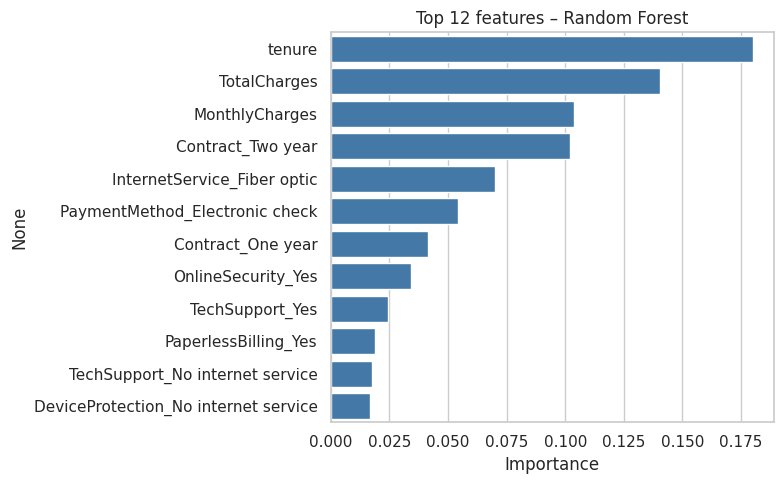

tenure                                  0.180
TotalCharges                            0.140
MonthlyCharges                          0.104
Contract_Two year                       0.102
InternetService_Fiber optic             0.070
PaymentMethod_Electronic check          0.054
Contract_One year                       0.042
OnlineSecurity_Yes                      0.034
TechSupport_Yes                         0.024
PaperlessBilling_Yes                    0.019
TechSupport_No internet service         0.017
DeviceProtection_No internet service    0.017
dtype: float64

In [15]:
rf = fitted["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#337AB7", ax=ax)
ax.set_title("Top 12 features – Random Forest")
ax.set_xlabel("Importance")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/07_feature_importance.png", dpi=150)
plt.show()
imp.round(3)

In [16]:
lr = fitted["Logistic Regression"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
print("Features that push towards CHURN (largest positive coefficients):")
print(coef.tail(6).round(2))
print("\nFeatures that push towards STAYING (largest negative coefficients):")
print(coef.head(6).round(2))

Features that push towards CHURN (largest positive coefficients):
PaperlessBilling_Yes              0.34
StreamingTV_Yes                   0.40
PaymentMethod_Electronic check    0.40
StreamingMovies_Yes               0.42
TotalCharges                      0.49
InternetService_Fiber optic       1.22
dtype: float64

Features that push towards STAYING (largest negative coefficients):
Contract_Two year    -1.41
tenure               -1.16
Contract_One year    -0.72
MonthlyCharges       -0.55
PhoneService_Yes     -0.35
OnlineSecurity_Yes   -0.33
dtype: float64


## 8. Score customers by churn risk

The selected model gives each customer in the held-out test split a churn probability, which is grouped into a risk band. These are retrospective test-set examples, not a live outreach list. A retention team could start by reviewing the High band. For a formal evaluation, model choice should be made with cross-validation or a validation set and the test set should be used only for final evaluation.

In [17]:
Xte = X_test_s if best_scaled else X_test
scored = df.loc[X_test.index, ["customerID", "Contract", "tenure", "MonthlyCharges", "Churn"]].copy()
scored["ChurnProbability"] = best_model.predict_proba(Xte)[:, 1]
scored["RiskBand"] = pd.cut(scored["ChurnProbability"], bins=[0, 0.3, 0.6, 1.0],
                            labels=["Low", "Medium", "High"], include_lowest=True)

summary = scored.groupby("RiskBand", observed=True).agg(
    Customers=("customerID", "count"),
    ActualChurnRate=("Churn", "mean"),
    AvgMonthlyCharge=("MonthlyCharges", "mean")).round(2)
summary["ActualChurnRate"] = (summary["ActualChurnRate"] * 100).round(1)
summary

,Customers,ActualChurnRate,AvgMonthlyCharge
RiskBand,,,
Low,685,7.0,53.47
Medium,351,28.0,72.65
High,373,61.0,75.53


In [18]:
top_risk = (scored[scored["Churn"] == 0].sort_values("ChurnProbability", ascending=False)
            [["customerID", "Contract", "tenure", "MonthlyCharges", "ChurnProbability"]].head(10))
top_risk.round(3)

,customerID,Contract,tenure,MonthlyCharges,ChurnProbability
2927,5542-TBBWB,Month-to-month,1,69.90,0.956
3346,2545-EBUPK,Month-to-month,2,84.05,0.951
4039,8161-QYMTT,Month-to-month,7,94.10,0.937
2493,8622-ZLFKO,Month-to-month,6,90.75,0.915
2519,4927-WWOOZ,Month-to-month,2,91.45,0.909
5019,3320-VEOYC,Month-to-month,14,95.60,0.900
5905,1628-BIZYP,Month-to-month,1,85.00,0.897
3885,4090-KPJIP,Month-to-month,3,74.95,0.894
3536,2254-DLXRI,Month-to-month,1,79.15,0.893
2350,8739-XNIKG,Month-to-month,5,84.00,0.893


## 9. Findings and recommendations

1. **Contract type matters most.** Month-to-month customers churn far more than those on one- or two-year contracts. Offer discounts or perks to move them onto longer plans.
2. **The first year is the danger zone.** Churn is highest in the first 12 months and falls steadily after that. A better onboarding experience and early check-ins should help.
3. **Fiber optic customers churn more**, and they also pay more. Worth checking service quality and price for this group.
4. **Support add-ons keep customers.** Customers without tech support or online security leave more often. Bundling these for free in the first months could reduce churn.
5. **Electronic check payers churn more** than customers on automatic payments. Encouraging auto-pay is a cheap retention step.
6. **Use the risk scores.** The model separates high-risk and low-risk customers well, so retention offers can be targeted instead of sent to everyone.

**Limitations:** the data is a single snapshot, so we can show which customers are at risk but not prove causes. The model should be retrained on fresh data regularly.

**Model-selection caveat:** this compact demonstration chooses among models using the comparison split. For a stricter final estimate, select the model using cross-validation or a separate validation split and evaluate it once on an untouched test set.
